# 08-03 - Does the Graph Help?

You read the lecture's experiment on whether the street graph helps to guess a speed limit, run new draws of it yourself, and look at the map it fills in.

First the lecture's table and what one score is worth. Then your own draws, no features, the road class, more labels and the split by blocks. Then who is tagged, the map filled in and a street you know. At the end a lattice and your turn.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import graph_tools as gt
import time

plt.rcParams["figure.dpi"] = 72

scene = gt.load_json("data/scene.json")
reference = gt.load_json("data/ground_truth.json")["p08"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
torch_ok, pyg_ok = gt.torch_ok, gt.pyg_available()
streets, metr = lecture["streets"], lecture["metr"]
print(f"seed {scene['seed']}; {streets['n']:,} street segments, {streets['tagged']} with a speed limit")
print(f"{metr['sensors']} traffic sensors; PyTorch {'ready' if torch_ok else 'missing'}, "
      f"PyTorch Geometric {'ready' if pyg_ok else 'missing'}")

seed 20261116; 1,219 street segments, 454 with a speed limit
207 traffic sensors; PyTorch ready, PyTorch Geometric ready


## The lecture's table

The cell loads the street segments and the lecture's runs, prints the mean of twenty draws for every feature set and graph, and draws them with their spread.

geometry and embedding none  66.4   proximity  69.5   streets  77.9   
with the road class    none  70.5   proximity  73.0   streets  77.9   
road class only        none  61.2   proximity  61.6   streets  61.0   
none                   none  61.3   proximity  66.4   streets  78.6   
majority rule 61.3; 150 labelled, 204 test


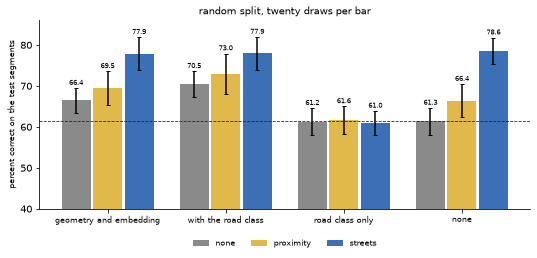

In [2]:
s, segments = gt.load_arrays("data/streets.npz"), gt.load_segments("data/streets.gpkg")
P, F = gt.street_graphs(s), gt.street_features(s, scene["choices"]["live_features"])
runs = gt.load_json("data/lecture_runs.json")
table, graphs = runs["table"]["random"], ("none", "proximity", "streets")
groups = {f: {g: table[f"{f}|{g}"]["draws"] for g in graphs} for f in gt.FEATURE_SETS}
for f, row in groups.items():
    print(f"{f:23s}" + "".join(f"{g} {100 * np.mean(v):5.1f}   " for g, v in row.items()))
print(f"majority rule {100 * table['majority']:.1f}; {table['labelled']} labelled, {table['test']} test")
ax = gt.show_bars(groups, baseline=table["majority"], title="random split, twenty draws per bar")

Each row is a set of features, each colour a graph, and all three models have the same layers and the same number of weights. With geometry and embedding the street graph lifts 66.4 to 77.9, while the proximity graph, which joins as many pairs by distance, reaches 69.5. The dashed line is the majority rule at 61.3, which names every segment 25 mph or less. Whiskers show one standard deviation. The road class alone stays on the dashed line, and with no features the street graph scores 78.6.

## One score is one draw

The cell prints the twenty draws behind one bar, their spread, and how often the street graph lost to the model without a graph on the same draw.

street graph, sorted: 68.1 70.6 71.6 76.0 77.0 77.0 77.5 77.5 77.9 78.4 78.4 78.4 79.4 79.9 79.9 79.9 81.4 82.4 83.3 83.3
mean 77.9, standard deviation 4.0, from 68.1 to 83.3
no graph from 60.8 to 71.1; the street graph lost on 0 of 20 draws


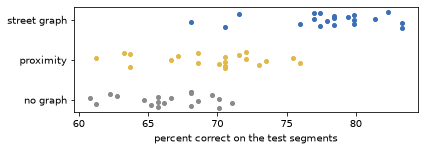

In [3]:
draws = {g: 100 * np.array(table[f"geometry and embedding|{g}"]["draws"]) for g in graphs}
print("street graph, sorted:", " ".join(f"{v:.1f}" for v in np.sort(draws["streets"])))
st = gt.summary(draws["streets"])
print(f"mean {st['mean']:.1f}, standard deviation {st['sd']:.1f}, from {st['min']:.1f} to {st['max']:.1f}")
print(f"no graph from {draws['none'].min():.1f} to {draws['none'].max():.1f}; "
      f"the street graph lost on {(draws['streets'] < draws['none']).sum()} of 20 draws")
fig, ax = plt.subplots(figsize=(6, 2.2))
for k, g in enumerate(graphs):
    ax.plot(draws[g], k + np.linspace(-0.2, 0.2, 20), "o", ms=4, color=gt.GRAPH_COLOURS[g])
ax.set_yticks(range(3), ["no graph", "proximity", "street graph"])
ax.set_xlabel("percent correct on the test segments")
fig.tight_layout()

A draw is one choice of the 150 labelled segments and one start of the weights, and draw number d is the same split for all three models. The street graph's twenty scores spread over about fifteen points, so a single run could have shown a gain of three points or of twenty. The count of lost draws says how often the graph was the worse choice on the very same split. That is why the table reports a mean and a spread, never one run.

## Your own draws

The cell trains the three models on five draws the lecture never used, numbers 20 to 24, and prints their mean beside the lecture's twenty.

In [4]:
if torch_ok:
    n, first = scene["choices"]["live_draws"], scene["choices"]["first_new_draw"]
    start = time.time()
    mine = {g: gt.run_draws(s, F, P[g], "random", draws=n, first=first)["accuracy"] for g in P}
    for g, v in mine.items():
        ref = table[f"geometry and embedding|{g}"]["accuracy"]
        print(f"{g:9s} draws {first} to {first + n - 1}: mean {100 * np.mean(v):5.1f}, "
              f"sd {100 * np.std(v, ddof=1):3.1f}   lecture's twenty {100 * ref['mean']:5.1f}, "
              f"sd {100 * ref['sd']:3.1f}")
    print(f"{3 * n} training runs in {time.time() - start:.0f} s")
else:
    print(gt.NO_TORCH)

none      draws 20 to 24: mean  67.9, sd 3.5   lecture's twenty  66.4, sd 3.0
proximity draws 20 to 24: mean  68.8, sd 5.0   lecture's twenty  69.5, sd 4.1
streets   draws 20 to 24: mean  75.2, sd 5.7   lecture's twenty  77.9, sd 4.0
15 training runs in 5 s


Fifteen networks are trained here, five per graph, on one thread so the numbers repeat on any laptop. Compare each mean with the lecture's on the same line. Five draws are fewer than twenty, so your means may sit a few points away from 66.4, 69.5 and 77.9, and the spread tells you how far is still normal. What should survive is the order, the street graph clearly first and the proximity graph a little above no graph.

## No features at all

The cell gives every segment only its own column of zeros and a one, trains the three models on three new draws and prints them beside the lecture's.

In [5]:
if torch_ok:
    F_none = gt.street_features(s, "none")
    print(f"{F_none.shape[1]:,} features per segment, one per segment; the lecture's GCN on them has "
          f"{lecture['numbers']['st none params']} weights")
    for g in P:
        v = gt.run_draws(s, F_none, P[g], "random", draws=3, first=first)["accuracy"]
        ref = table[f"none|{g}"]["accuracy"]["mean"]
        print(f"{g:9s} three new draws {100 * np.mean(v):5.1f}   lecture's twenty {100 * ref:5.1f}")
else:
    print(gt.NO_TORCH)

1,219 features per segment, one per segment; the lecture's GCN on them has 39,172 weights


none      three new draws  63.2   lecture's twenty  61.3


proximity three new draws  68.5   lecture's twenty  66.4


streets   three new draws  78.9   lecture's twenty  78.6


Without features a segment is just a name, so the model without a graph can only learn the labelled segments by heart and name every new one by the most common class, 61.3 in the lecture. The street graph changes that. Its first layer mixes each segment's column with its neighbours', so a test segment inherits the weights learned for the labelled segments within two steps. The lecture's 78.6 means the speed limit is carried by what a segment connects to. The proximity graph, at 66.4, passes far less along.

## The road class as a feature

The cell prints the gain from adding the road class for each graph, and how the road classes of the tagged segments split over the four speed limits.

In [6]:
for g in graphs:
    a, b = (100 * table[f"{f}|{g}"]["accuracy"]["mean"] for f in gt.FEATURE_SETS[:2])
    c = 100 * table[f"road class only|{g}"]["accuracy"]["mean"]
    print(f"{g:9s} geometry and embedding {a:.1f}, with the road class {b:.1f} ({b - a:+.1f}), "
          f"road class only {c:.1f}")
tag = s["tagged"]
M = gt.confusion(s["y"][tag], s["road_class"][tag], 4)
print(f"\n{'tagged segments':17s}" + "".join(f"{n:>16s}" for n in s["speed_names"]))
for name, row in zip(s["road_names"], M):
    print(f"{name:17s}" + "".join(f"{v:16d}" for v in row))

none      geometry and embedding 66.4, with the road class 70.5 (+4.0), road class only 61.2
proximity geometry and embedding 69.5, with the road class 73.0 (+3.5), road class only 61.6
streets   geometry and embedding 77.9, with the road class 77.9 (+0.0), road class only 61.0

tagged segments    25 mph or less          30 mph          35 mph  40 mph or more
residential                   117               6               0               0
tertiary                      118              31              50              20
secondary                      29               4              14              15
primary or trunk               16              12              12              10


The road class, residential up to primary, gives the model without a graph four points and the street graph nothing. The street graph already knew it, since a segment's neighbours along the same road share its class. The table below explains why the road class alone stays at the majority rule. The residential and tertiary rows, which hold most tagged segments, are dominated by 25 mph or less, so the best guess from the class is that label for them.

## More labels

The cell draws the lecture's curve of accuracy against the number of labelled segments, from 10 to 250, for the three graphs.

none      10: 44.4  20: 50.7  40: 57.5  80: 61.2  150: 67.3  250: 69.7
proximity 10: 48.8  20: 53.3  40: 59.8  80: 62.8  150: 70.4  250: 71.8
streets   10: 53.2  20: 57.5  40: 64.4  80: 68.9  150: 80.0  250: 82.9


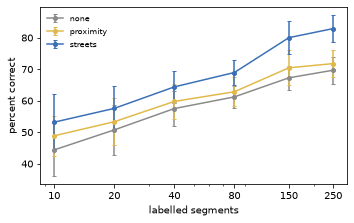

In [7]:
lab = runs["labels"]
sizes = sorted({int(k.split("|")[0]) for k in lab})
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for g in graphs:
    m = [100 * lab[f"{k}|{g}"]["mean"] for k in sizes]
    e = [100 * lab[f"{k}|{g}"]["sd"] for k in sizes]
    ax.errorbar(sizes, m, yerr=e, marker="o", ms=4, capsize=2, color=gt.GRAPH_COLOURS[g], label=g)
    print(f"{g:9s}", "  ".join(f"{k}: {v:.1f}" for k, v in zip(sizes, m)))
ax.set_xscale("log")
ax.set(xticks=sizes, xticklabels=sizes, xlabel="labelled segments", ylabel="percent correct")
lines = ax.legend(frameon=False, fontsize=8)

With ten labels the street graph reaches 53.2 against 44.4 without a graph, and the gap widens as labels are added, to 82.9 against 69.7 at 250. The graph helps more, not less, with more labels, because every new label also informs its neighbours. The curve scores every size on the same 104 test segments, so its value at 150 differs from the table's 77.9, which used all 204 test segments of each draw.

## The split by blocks

The cell draws the same table for the split by Lecture 04's held-out blocks, where the test segments lie inside the blocks and the labels outside.

geometry and embedding none  63.3   proximity  62.9   streets  60.6   
with the road class    none  66.0   proximity  62.3   streets  58.7   
road class only        none  61.2   proximity  60.7   streets  53.7   
none                   none  66.5   proximity  59.6   streets  67.2   
majority rule 66.5; 100 labelled, 200 test


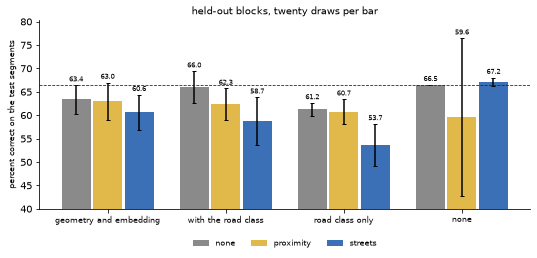

In [8]:
blocks = runs["table"]["blocks"]
groups_b = {f: {g: blocks[f"{f}|{g}"]["draws"] for g in graphs} for f in gt.FEATURE_SETS}
for f, row in groups_b.items():
    print(f"{f:23s}" + "".join(f"{g} {100 * np.mean(v):5.1f}   " for g, v in row.items()))
print(f"majority rule {100 * blocks['majority']:.1f}; {blocks['labelled']} labelled, {blocks['test']} test")
ax = gt.show_bars(groups_b, baseline=blocks["majority"], title="held-out blocks, twenty draws per bar")

The picture changes completely. The majority rule now scores 66.5, because the blocks hold many quiet streets, and no bar stands clearly above the dashed line. The graphs do not help and even cost a few points, the street graph with the road class at 58.7 against 66.0 without a graph. The model without features gives exactly the majority on every draw, and the wild whisker of the proximity graph without features shows draws that fell far below it.

## Why the blocks defeat the graph

The cell takes draw 0 of both splits and counts the test segments that have a labelled segment within two steps on the street graph.

random: 150 labelled, 204 test, 91% of the test segments within two steps of a label, median 1 steps
blocks: 100 labelled, 200 test, 8% of the test segments within two steps of a label, median 7 steps


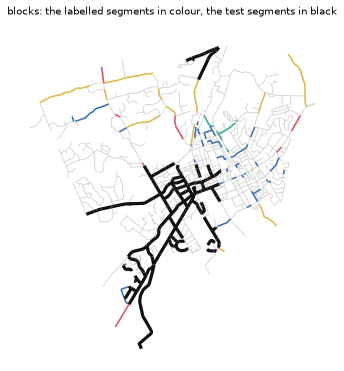

In [9]:
y = gt.street_classes(s)
for kind in ("random", "blocks"):
    n_lab = rules["streets"]["n_labelled_blocks" if kind == "blocks" else "n_labelled"]
    lab_i, val_i, test_i = gt.split_streets(s, kind, np.random.default_rng(gt.SEED + 100), n_lab)
    marked = np.isin(np.arange(len(y)), lab_i)
    steps = gt.steps_to(s["A_street"], marked)
    near = ((steps[test_i] >= 0) & (steps[test_i] <= 2)).mean()
    print(f"{kind:6s}: {len(lab_i)} labelled, {len(test_i)} test, {near:.0%} of the test segments within two "
          f"steps of a label, median {np.median(steps[test_i]):.0f} steps")
ax = gt.show_streets(segments, classes=np.where(marked, y, -1), mark=test_i, legend=False,
                     title="blocks: the labelled segments in colour, the test segments in black")

A two-layer GCN hears only the segments within two steps. On the random split most test segments have a label that close, so the graph can pass it on. On the block split the black test segments sit together inside the blocks, and only few of them have a label within reach, the rest lie further away than two layers can hear. There is nothing to pass, and the features alone do not tell a 30 from a 25.

## Who is tagged

The cell counts, for each road class, how many segments carry a speed limit on the map, beside the lecture's shares.

In [10]:
for k, name in enumerate(s["road_names"]):
    here = s["road_class"] == k
    ref = lecture["streets"]["tagged_by_road_class"][name]
    print(f"{name:17s} {here.sum():4d} segments, {s['tagged'][here].sum():4d} tagged, "
          f"{s['tagged'][here].mean():4.0%}   lecture {ref:.0%}")
untagged = ~s["tagged"]
print(f"of the {untagged.sum()} untagged segments, {(s['road_class'][untagged] == 0).sum()} are residential")

residential        832 segments,  123 tagged,  15%   lecture 15%
tertiary           263 segments,  219 tagged,  83%   lecture 83%
secondary           71 segments,   62 tagged,  87%   lecture 87%
primary or trunk    53 segments,   50 tagged,  94%   lecture 94%
of the 765 untagged segments, 709 are residential


Only 15 percent of the residential segments carry a limit, against 83 to 94 percent of the larger roads, because mappers tag the main roads first. Almost all untagged segments are residential. So every score above was measured on segments like the tagged ones, mostly larger roads, and a prediction for a quiet street is an extrapolation. This is the dataset shift of Lecture 04 again, and no score on the tagged segments can measure it.

## The map filled in

The cell loads the lecture's run that trained on 354 tagged segments, counts its guesses for the untagged ones and draws both maps.

street graph 595 25 mph or less, 62 30 mph, 85 35 mph, 23 40 mph or more   lecture [595, 62, 85, 23]
no graph     683 25 mph or less, 12 30 mph, 59 35 mph, 11 40 mph or more   lecture [683, 12, 59, 11]


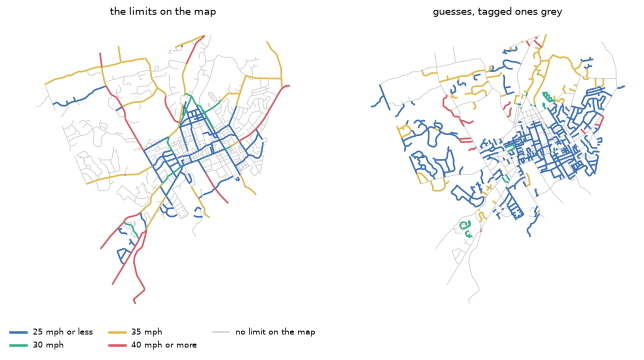

In [11]:
main = gt.load_arrays("data/lecture_main.npz")
fill = lecture["main"]["fill"]
for k, name in (("gcn", "street graph"), ("mlp", "no graph")):
    counts = np.bincount(main[f"fill_{k}_pred"][untagged], minlength=4)
    print(f"{name:12s}", ", ".join(f"{c} {n}" for c, n in zip(counts, s["speed_names"])),
          f"  lecture {fill[k]['untagged_per_class']}")
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
ax = gt.show_streets(segments, classes=s["y"], ax=axes[0], title="the limits on the map")
guesses = np.where(untagged, main["fill_gcn_pred"], -1)
ax = gt.show_streets(segments, classes=guesses, ax=axes[1], legend=False, title="guesses, tagged ones grey")

The left map shows the tags alone, the right map only the guesses in the same colours. The street graph names 595 segments 25 mph or less, 62 at 30, 85 at 35 and 23 at 40 or more. The model without a graph puts 683 into the first class and only 12 at 30. Look at the right map near the coloured roads on the left. The guesses continue a tagged road into its untagged pieces, which is exactly what the graph passes along.

## How sure the model is

The cell takes the largest class probability of every untagged segment for both models and relates it to the distance in steps to the nearest tagged segment.

street graph sure to 90 percent on 563, lecture 563
no graph     sure to 90 percent on 339, lecture 339
within one step of a tag 298, within two 528   lecture 298 and 528
street graph's mean certainty at 1, 2, 3, 4 or more steps from a tag: 0.91 0.94 0.92 0.84


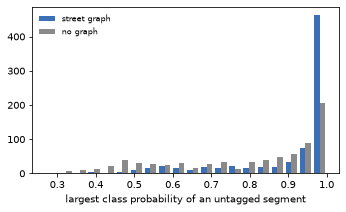

In [12]:
sure = {k: main[f"fill_{k}_prob"][untagged].max(1) for k in ("gcn", "mlp")}
for k, name in (("gcn", "street graph"), ("mlp", "no graph")):
    print(f"{name:12s} sure to 90 percent on {(sure[k] >= 0.9).sum()}, lecture {fill[k]['confident_90']}")
far = np.minimum(main["steps_to_tagged"][untagged], 4)
print(f"within one step of a tag {(far == 1).sum()}, within two {(far <= 2).sum()}   "
      f"lecture {fill['untagged_within_1']} and {fill['untagged_within_2']}")
print("street graph's mean certainty at 1, 2, 3, 4 or more steps from a tag:",
      " ".join(f"{sure['gcn'][far == k].mean():.2f}" for k in range(1, 5)))
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.hist([sure["gcn"], sure["mlp"]], bins=20, color=["#3b6fb6", "#8a8a8a"], label=["street graph", "no graph"])
ax.set_xlabel("largest class probability of an untagged segment")
lines = ax.legend(frameon=False, fontsize=8)

The street graph is at least 90 percent sure on 563 of the 765 untagged segments, the model without a graph on 339, the tall blue bar at the right. The mean certainty barely changes within three steps of a tag and drops only beyond. A high probability only means that the inputs and the neighbours point one way. A model trained on biased labels can be sure and wrong, and nothing here can check it, since the untagged segments have no limit to score against.

## Check a street you know

Put the streets you know into the list. The cell prints each street's segments, the untagged and the least sure first, with tag, guess, certainty and steps to a tag.

In [13]:
STREETS = anchors["streets_to_check"]
names, pred, prob = s["speed_names"], main["fill_gcn_pred"], main["fill_gcn_prob"].max(1)
for street in STREETS:
    idx = gt.lookup_street(s, street)
    order = idx[np.lexsort((prob[idx], s["tagged"][idx]))]
    hits = (pred[idx] == s["y"][idx]).sum()
    print(f"{street}: {len(idx)} segments, {s['tagged'][idx].sum()} tagged, the guess matches {hits} tags")
    for i in order[:6]:
        tag = names[s["y"][i]] if s["tagged"][i] else "no limit"
        print(f"   {i:5d} {s['name'][i].strip("[]'")[:24]:24s} tag {tag:15s} guess {names[pred[i]]:15s} "
              f"{prob[i]:4.0%} sure, steps to a tag {main['steps_to_tagged'][i]}")

Nassau Street: 29 segments, 29 tagged, the guess matches 28 tags
     660 Nassau Street            tag 35 mph          guess 30 mph           48% sure, steps to a tag 0
     364 Nassau Street            tag 35 mph          guess 35 mph           55% sure, steps to a tag 0
     241 Nassau Street            tag 30 mph          guess 30 mph           72% sure, steps to a tag 0
     662 Nassau Street            tag 30 mph          guess 30 mph           73% sure, steps to a tag 0
     369 Nassau Street            tag 35 mph          guess 35 mph           76% sure, steps to a tag 0
     682 Nassau Street            tag 30 mph          guess 30 mph           79% sure, steps to a tag 0
Witherspoon Street: 17 segments, 15 tagged, the guess matches 15 tags
     510 Witherspoon Street       tag no limit        guess 25 mph or less  100% sure, steps to a tag 1
     517 Witherspoon Street       tag no limit        guess 25 mph or less  100% sure, steps to a tag 1
     767 Witherspoon Street      

The default list holds three streets that are tagged almost everywhere, and on those segments the model mostly repeats the labels it was trained on, so a match there proves little. The interesting lines say no limit. Hold each guess against the sign you have walked past. A predicted limit is a hint that tells a mapper where to look, and never a legal fact, since the town or the state sets the limit. A name the map does not know prints zero segments.

## Where the two models disagree

The cell finds the untagged segments where the street graph and the model without a graph name different classes, counts the pairs and maps them.

148 untagged segments get different classes   lecture 148
no graph says      25 mph or less          30 mph          35 mph  40 mph or more   (street graph says)
25 mph or less                569              48              51              15
30 mph                          1              11               0               0
35 mph                         24               0              32               3
40 mph or more                  1               3               2               5


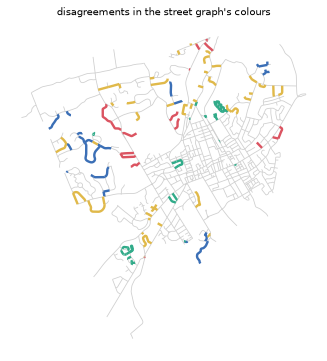

In [14]:
differ = untagged & (main["fill_gcn_pred"] != main["fill_mlp_pred"])
print(f"{differ.sum()} untagged segments get different classes   lecture {fill['disagree']}")
M = gt.confusion(main["fill_gcn_pred"], main["fill_mlp_pred"], 4, idx=np.nonzero(untagged)[0])
print(f"{'no graph says':17s}" + "".join(f"{n:>16s}" for n in names) + "   (street graph says)")
for name, row in zip(names, M):
    print(f"{name:17s}" + "".join(f"{v:16d}" for v in row))
ax = gt.show_streets(segments, classes=np.where(differ, main["fill_gcn_pred"], -1), lw=2.4, legend=False,
                     title="disagreements in the street graph's colours")

On 148 untagged segments the graph changed the answer. The table says how. Rows are the model without a graph, columns the street graph, and the large numbers off the diagonal in the first row are segments the model without a graph called 25 mph or less and the street graph raised to 30 or 35. On the map they sit mostly at the edges of town, on short pieces beside a road with a higher tag. These are the segments where a check on the ground pays off most.

## The same question on a lattice

The cell prints the lecture's backup table for 782 grid cells, where the label is the land use and the graph joins cells by their sides or by a walk.

In [15]:
cells = runs["cells"]
info = cells["info"]
print(f"{info['n']} cells, {info['m_side']} side edges, {info['m_walk']} walk edges")
for split in ("random", "blocks"):
    t = cells["table"][split]
    print(f"{split} split, majority rule {100 * t['majority']:.1f}")
    for f in ("embedding", "built fraction", "none"):
        row = [100 * t[f"{f}|{g}"]["accuracy"]["mean"] for g in ("none", "sides", "walk")]
        print(f"   {f:15s} no graph {row[0]:5.1f}   sides {row[1]:5.1f}   walk {row[2]:5.1f}")

782 cells, 1478 side edges, 1035 walk edges
random split, majority rule 50.5
   embedding       no graph  71.0   sides  69.4   walk  71.2
   built fraction  no graph  59.2   sides  57.0   walk  60.7
   none            no graph  50.5   sides  64.1   walk  56.8
blocks split, majority rule 39.7
   embedding       no graph  56.7   sides  54.9   walk  55.7
   built fraction  no graph  42.4   sides  52.3   walk  50.2
   none            no graph  39.7   sides  42.4   walk  41.8


With the satellite embedding the graph changes nothing, 56.7 without and 54.9 with the side graph on the held-out blocks. A cell's neighbours on a lattice are simply the cells around it, and the embedding already describes that surrounding area, so averaging over them adds nothing new. The graph helps only where a feature is noisy, the built fraction from 42.4 to 52.3, or where labels are near. A graph helps when its edges carry what the features lack.

## Your turn

Repeat your own draws of the three graphs on the split by held-out blocks, with 100 labelled segments. The cell prints each graph's mean over five new draws beside the majority rule. Run the cell as it is, then change the marked value and run it again.

On the block split, which graph scores best, and does any of them beat the majority rule? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [16]:
SPLIT = "random"  # change me: "blocks"
if torch_ok:
    n_lab = rules["streets"]["n_labelled_blocks" if SPLIT == "blocks" else "n_labelled"]
    for g in P:
        out = gt.run_draws(s, F, P[g], SPLIT, draws=n, first=first, n_labelled=n_lab)
        print(f"{SPLIT}, {g:9s} mean of {n} new draws {100 * np.mean(out['accuracy']):5.1f}   "
              f"majority rule {100 * np.mean(out['majority']):5.1f}")
else:
    print(gt.NO_TORCH)

random, none      mean of 5 new draws  67.9   majority rule  62.3


random, proximity mean of 5 new draws  68.8   majority rule  62.3


random, streets   mean of 5 new draws  75.2   majority rule  62.3


## Check your understanding

1. Your five draws and the lecture's twenty gave different means. When would you call such a difference real?
2. A fair baseline for a graph model needs the same weights, the same split, the spread over draws and the tagged share. Say for each why the comparison misleads without it.
3. Without features the street graph scores as well as with them. What does it learn from, and why can the proximity graph not?
4. Only 15 percent of the residential segments are tagged. Why is the street graph's high certainty on the rest no evidence that its guesses are right?

## Where we are

You have read the lecture's table draw by draw, trained new draws of the three graphs, removed every feature, added the road class and more labels, and watched the graph stop helping on the held-out blocks. Then you filled in the map, asked how sure it is, checked a street you know and saw why a lattice gains nothing. In 08-04 the nodes become traffic sensors in Los Angeles, and the question is whether the neighbours' readings improve a forecast.

## Further resources

Nothing in this course requires anything below.

- Pitfalls of Graph Neural Network Evaluation, Oleksandr Shchur, Maximilian Mumme, Aleksandar Bojchevski and Stephan Günnemann, arXiv 2018, https://arxiv.org/abs/1811.05868, on why one split and one run mislead
- Semi-Supervised Classification with Graph Convolutional Networks, Thomas Kipf and Max Welling, ICLR 2017, https://arxiv.org/abs/1609.02907
- Graph Representation Learning, William L. Hamilton, Morgan and Claypool 2020, chapter 6, pages 69 to 70, https://www.cs.mcgill.ca/~wlh/grl_book/

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The street segments, their names and their speed limits derive from OpenStreetMap, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright The 64 embedding numbers of every segment come from the AlphaEarth Foundations Satellite Embedding dataset, produced by Google and Google DeepMind, CC BY 4.0.